# Time-series anomaly detection: Isolation Forest + LSTM

Trains two detectors on multivariate sensor logs (CSV). Long-format logs (one row per timestamp/asset/metric) are pivoted to one column per asset+metric. If a 0/1 attack label is available it is used only to keep attack data out of training and to evaluate; the models themselves never see it as an input.

1. **Isolation Forest** on engineered rolling features
2. **LSTM forecaster** that predicts the next sample from a window of history; large prediction error = anomaly
3. **Autoencoder** that compresses a short window of all features and reconstructs it; large reconstruction error = anomaly. It learns how the features relate to each other, which suits attacks that look plausible on their own but are inconsistent with the other signals

**Running on Bitdeer:** start a GPU instance with a PyTorch/JupyterLab image, upload `train.csv`, `validation.csv`, and `test.csv` (or their `.csv.gz` versions) next to this notebook, edit the **Config** cell, then run all cells. Everything is saved to `outputs/`, so download that folder when finished.

Both models train on the supplied training file, select thresholds using the validation file, and are evaluated on the test file. File membership is preserved; no percentage split is created. Upload the training file before running all cells.

In [4]:
%pip install -q scikit-learn pandas numpy matplotlib joblib
try:
    import torch
except ImportError:
    %pip install -q torch

Note: you may need to restart the kernel to use updated packages.


In [5]:
import json, os, time, random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import StandardScaler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cpu 


## Config
Edit this cell. Everything else should work unchanged.

In [19]:
# ---- Data ----
CSV_PATHS = {"train": "train.csv", "val": "validation.csv", "test": "test.csv"}
LONG_FORMAT    = True          # True: one row per (timestamp, asset, metric) -> pivoted to one column per pair
TIMESTAMP_COL  = "simulated_at"
VALUE_COL      = "value"       # long format only
ID_COLS        = ["asset_id", "metric"]   # long format only: each unique pair becomes one feature
FACILITY_COL   = "facility_id" # long format only: always prefixed to feature names when configured; None to ignore
FEATURE_COLS   = None          # wide format only: list of columns, or None for every numeric column
LABEL_COL      = "is_attack"   # 0/1 per row; used for evaluation (and optionally to clean the training data)
RESAMPLE_RULE  = "1min"        # resample to a fixed interval (e.g. "1min"), or None to skip
MAX_GAP_FILL   = 5             # max consecutive missing steps to interpolate after resampling
TRAIN_ON_NORMAL_ONLY = True    # drop attack rows/windows from training and early-stopping loss (needs LABEL_COL)

# ---- Isolation Forest ----
ROLL_WINDOWS   = [10, 60]   # rolling mean/std windows (samples); long ones catch drift and daily-profile deviations
CONTEXT_PATTERNS = ["outdoor_temperature"]  # columns containing these strings are given to EVERY asset's forest as context
IF_N_TREES     = 200
IF_MAX_SAMPLES = 256
IF_FIT_FRAC    = 0.8           # forests fit on the first 80% of train; the last 20% calibrates scores out-of-sample
AGG_TOPK       = 1             # system score = mean of the top-k asset scores (1 = plain max)
THRESHOLD_METHOD = "validation_f1"   # "validation_f1" (needs labels in val) or "normal_percentile"
THRESHOLD_PCTL = 99.5          # percentile of normal validation scores (fallback / normal_percentile)
VAL_PREVALENCE = None          # expected attack share in real use (e.g. 0.03). If set, validation F1 is computed as if attacks were
                               # this share of the data. Use it when validation's attack share (here ~30%) differs from reality.

# ---- LSTM ----
WINDOW         = 60            # history length fed to the LSTM
HIDDEN         = 128
LAYERS         = 3
DROPOUT        = 0.2
EPOCHS         = 50
BATCH_SIZE     = 256
LR             = 5e-4
PATIENCE       = 8             # early stopping on validation loss
LSTM_TOPK      = 3             # per-feature LSTM score = mean of the k largest standardized feature errors (1 = max)

# ---- Autoencoder ----
RUN_AUTOENCODER = True
AE_WINDOW      = 10            # consecutive timesteps fed together (1 = one timestep at a time)
AE_HIDDEN      = 256
AE_BOTTLENECK  = 32            # size of the compressed code; smaller = more compression, less chance of copying its input
AE_DROPOUT     = 0.1
AE_NOISE       = 0.05          # Gaussian noise added to inputs during training (denoising autoencoder); 0 to disable
AE_EPOCHS      = 60
AE_BATCH       = 256
AE_LR          = 1e-3
AE_PATIENCE    = 8
AE_TOPK        = 3             # per-feature score = mean of the k largest standardized feature errors (1 = max)
AE_MODEL = "gru"

SEED       = 42
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## 1. Load the supplied train, validation, and test files

Features are aligned to training columns, and scaling is fitted on training data only. Each file is resampled and filled separately.


In [7]:
# Each file supplies its own split. Compressed CSVs are also supported.
paths = {}
for name, filename in CSV_PATHS.items():
    path = Path(filename)
    if not path.is_file():
        path = Path(str(path) + ".gz")
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {name} dataset: upload {filename} (or {filename}.gz) beside the notebook."
        )
    paths[name] = path


def load_split(path):
    if LONG_FORMAT:
        # Only read the columns we need. original_value, attack_kind and energyplus_key are deliberately
        # NOT loaded: they reveal whether/how a row was tampered with and would leak the labels.
        use = [TIMESTAMP_COL, VALUE_COL] + ID_COLS
        if FACILITY_COL: use.append(FACILITY_COL)
        if LABEL_COL:    use.append(LABEL_COL)
        raw = pd.read_csv(path, usecols=list(dict.fromkeys(use)))
        print("Raw long-format rows:", f"{len(raw):,}")
        raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], errors="coerce")
        raw = raw.dropna(subset=[TIMESTAMP_COL, VALUE_COL])
    
        key_cols = ([FACILITY_COL] if FACILITY_COL else []) + ID_COLS
        feature = raw[key_cols[0]].astype(str)
        for c in key_cols[1:]:
            feature = feature + "__" + raw[c].astype(str)
        raw["feature"] = feature.astype("category")
    
        X = (raw.groupby([TIMESTAMP_COL, "feature"], observed=True)[VALUE_COL].mean()
                .unstack("feature").sort_index().astype("float32"))
        y = raw.groupby(TIMESTAMP_COL)[LABEL_COL].max().reindex(X.index) if LABEL_COL else None
        del raw
    else:
        df = pd.read_csv(path)
        df[TIMESTAMP_COL] = pd.to_datetime(df[TIMESTAMP_COL], errors="coerce")
        df = (df.dropna(subset=[TIMESTAMP_COL]).sort_values(TIMESTAMP_COL)
                .drop_duplicates(TIMESTAMP_COL).set_index(TIMESTAMP_COL))
        cols = FEATURE_COLS or [c for c in df.select_dtypes("number").columns if c != LABEL_COL]
        X = df[cols].astype("float32")
        y = df[LABEL_COL].astype("float32") if LABEL_COL else None
    
    if X.empty:
        raise ValueError(f"No usable rows in {path}")
    if RESAMPLE_RULE:
        X = X.resample(RESAMPLE_RULE).mean()
        y = y.resample(RESAMPLE_RULE).max() if y is not None else None
    if y is not None:
        y = y.fillna(0).astype(int)
        if not y.isin([0, 1]).all():
            raise ValueError(f"Non-binary attack labels in {path}")
    return X, y


data = {name: load_split(path) for name, path in paths.items()}
# Feature selection and fallback values come exclusively from training data.
train_X = data["train"][0].dropna(axis=1, how="all")
feat_cols = list(train_X.columns)
if not feat_cols:
    raise ValueError("Training data has no usable features")
fill_values = train_X.median()
for name, (frame, labels) in data.items():
    missing = set(feat_cols) - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing training features: {sorted(missing)[:10]}")
    frame = frame.reindex(columns=feat_cols)
    # Fill within each file only; never interpolate across split boundaries.
    frame = frame.interpolate(limit=MAX_GAP_FILL).ffill().fillna(fill_values)
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError(f"Non-finite features in {name}")
    if len(frame) <= WINDOW:
        raise ValueError(f"{name} needs more than {WINDOW} timesteps")
    data[name] = (frame, labels)
    print(f"{name}: {len(frame):,} timesteps, {len(feat_cols)} features, "
          f"{frame.index[0]} -> {frame.index[-1]}")

# Concatenation is only for downstream indexing; membership comes from the files.
X = pd.concat([data[name][0] for name in CSV_PATHS])
y = pd.concat([data[name][1] for name in CSV_PATHS]) if LABEL_COL else None
X.iloc[:3, :6]


Raw long-format rows: 8,956,800
Raw long-format rows: 2,239,200
Raw long-format rows: 2,239,200
train: 28,800 timesteps, 311 features, 2025-01-01 00:01:00 -> 2025-01-21 00:00:00
val: 7,200 timesteps, 311 features, 2025-01-21 00:01:00 -> 2025-01-26 00:00:00
test: 7,200 timesteps, 311 features, 2025-01-26 00:01:00 -> 2025-01-31 00:00:00


feature,guardfleet_warehouse__cooler_1__air_chiller_cooling_rate_w,guardfleet_warehouse__cooler_1__zone_relative_humidity_pct,guardfleet_warehouse__cooler_1__zone_temperature_c,guardfleet_warehouse__cooler_1airchiller_1__air_chiller_electric_power_w,guardfleet_warehouse__cooler_1airchiller_1__defrost_electric_power_w,guardfleet_warehouse__cooler_1airchiller_2__air_chiller_electric_power_w
simulated_at,,,,,,
2025-01-01 00:01:00,0.0,45.235245,3.593061,0.0,0.0,0.0
2025-01-01 00:02:00,0.0,44.840145,3.719243,0.0,0.0,0.0
2025-01-01 00:03:00,0.0,44.193066,3.927262,0.0,0.0,0.0


In [8]:
n = len(X)
i_train = len(data["train"][0])
i_val = i_train + len(data["val"][0])

scaler = StandardScaler().fit(X.iloc[:i_train])          # fit on training data only
S = pd.DataFrame(scaler.transform(X), index=X.index, columns=feat_cols).astype("float32")
S = S.clip(-10, 10)

splits = {"train": (0, i_train), "val": (i_train, i_val), "test": (i_val, n)}
for k, (a, b) in splits.items():
    msg = f"{k:5s}: rows {a:,}-{b:,}"
    if y is not None: msg += f"  anomalies: {int(y.iloc[a:b].sum())}"
    print(msg)

attack = (y.values == 1) if y is not None else np.zeros(n, dtype=bool)
USE_CLEAN = bool(TRAIN_ON_NORMAL_ONLY and y is not None)
print("Training on normal data only:", USE_CLEAN)

train: rows 0-28,800  anomalies: 0
val  : rows 28,800-36,000  anomalies: 2160
test : rows 36,000-43,200  anomalies: 210
Training on normal data only: True


## 2. Isolation Forest
One forest per facility/asset, each also given shared context (time of day, day of week, outdoor temperature). Each forest is fit on the first `IF_FIT_FRAC` of the training file (normal rows only); its scores are then centred and scaled with held-out normal training rows (median and 99th-percentile tail), so assets are comparable. The system score is the mean of the top `AGG_TOPK` asset scores. The threshold is chosen on the validation file; test data never calibrates scores or selects thresholds.

In [9]:
def choose_threshold(name, scores, labels):
    scores = np.asarray(scores, dtype=np.float64)
    if scores.ndim != 1 or not len(scores) or not np.isfinite(scores).all():
        raise ValueError(f"{name}: expected finite, non-empty scores")
    labels = None if labels is None else np.asarray(labels)
    if labels is not None and (labels.shape != scores.shape or not np.isin(labels, [0, 1]).all()):
        raise ValueError(f"{name}: validation labels must be aligned and binary")
    weights = None
    if VAL_PREVALENCE is not None and labels is not None and len(np.unique(labels)) == 2:
        if not 0 < VAL_PREVALENCE < 1:
            raise ValueError("VAL_PREVALENCE must be between 0 and 1")
        n_pos, n_neg = int((labels == 1).sum()), int((labels == 0).sum())
        # weight normal rows so attacks make up VAL_PREVALENCE of the weighted validation data
        weights = np.where(labels == 1, 1.0, n_pos * (1 - VAL_PREVALENCE) / (n_neg * VAL_PREVALENCE))
    if THRESHOLD_METHOD not in ("validation_f1", "normal_percentile"):
        raise ValueError("Unknown THRESHOLD_METHOD")
    if THRESHOLD_METHOD == "validation_f1" and labels is not None and len(np.unique(labels)) == 2:
        precision, recall, cutoffs = precision_recall_curve(labels, scores, sample_weight=weights)
        f1 = np.divide(2 * precision[:-1] * recall[:-1],
                       precision[:-1] + recall[:-1],
                       out=np.zeros_like(cutoffs), where=(precision[:-1] + recall[:-1]) > 0)
        # Highest cutoff wins ties, reducing alerts for equal validation F1.
        best = np.flatnonzero(f1 == f1.max())[-1]
        # sklearn uses >=; downstream alerts use >. Preserve the selected predictions.
        threshold = float(np.nextafter(cutoffs[best], -np.inf))
        method = "validation_f1"
    else:
        normal_scores = scores if labels is None else scores[labels == 0]
        if not len(normal_scores):
            raise ValueError(f"{name}: no normal validation samples for percentile fallback")
        if THRESHOLD_METHOD == "validation_f1":
            print(f"{name}: validation needs both classes; using normal percentile fallback")
        threshold = float(np.percentile(normal_scores, THRESHOLD_PCTL))
        method = "normal_percentile"
    print(f"{name} threshold: {threshold:.8g} ({method})")
    if labels is not None:
        flags = scores > threshold
        p, r, f, _ = precision_recall_fscore_support(labels, flags, average="binary", zero_division=0,
                                                     sample_weight=weights)
        flag_rate = float(np.average(flags, weights=weights))
        tag = f", reweighted to {VAL_PREVALENCE:.1%} attack share" if weights is not None else ""
        print(f"  Validation: precision {p:.3f}  recall {r:.3f}  F1 {f:.3f}  "
              f"flagged {flags.sum():,}/{len(flags):,} ({flag_rate:.2%}{tag})")
        if flag_rate > 0.30:
            print(f"  WARNING: {name} flags >30% of validation rows at its best threshold; the score carries little signal for these attacks")
    return threshold, method

val_labels = y.iloc[splits["val"][0]:splits["val"][1]].to_numpy() if y is not None else None

In [10]:
def make_features(S):
    parts = [S]
    for w in ROLL_WINDOWS:
        r = S.rolling(w, min_periods=1)
        parts.append(r.mean().add_suffix(f"_mean{w}"))
        parts.append(r.std().fillna(0).add_suffix(f"_std{w}"))
    parts.append(S.diff().fillna(0).add_suffix("_diff"))
    return pd.concat(parts, axis=1)

F_base = make_features(S)                      # causal: built once over the full series, sliced by split later

ctx = []
if isinstance(S.index, pd.DatetimeIndex):
    tod = (S.index.hour * 60 + S.index.minute) / 1440
    dow = S.index.day_of_week / 7
    ctx.append(pd.DataFrame({"tod_sin": np.sin(2 * np.pi * tod), "tod_cos": np.cos(2 * np.pi * tod),
                             "dow_sin": np.sin(2 * np.pi * dow), "dow_cos": np.cos(2 * np.pi * dow)}, index=S.index))
ctx_raw = [c for c in S.columns if any(p in c for p in CONTEXT_PATTERNS)]
if ctx_raw:
    ctx.append(S[ctx_raw])
    for w in ROLL_WINDOWS:
        ctx.append(S[ctx_raw].rolling(w, min_periods=1).mean().add_suffix(f"_mean{w}"))
F_ctx = pd.concat(ctx, axis=1) if ctx else pd.DataFrame(index=S.index)
F_ctx = F_ctx.loc[:, ~F_ctx.columns.duplicated()]
print("Context features:", list(F_ctx.columns))

F = pd.concat([F_base, F_ctx], axis=1)
F = F.loc[:, ~F.columns.duplicated()].astype("float32")
print("Engineered feature matrix:", F.shape)

# Per-asset grouping: long-format feature names are [facility__]asset__metric
if not LONG_FORMAT or ID_COLS != ["asset_id", "metric"]:
    raise ValueError("Per-asset grouping requires long format with ID_COLS=['asset_id', 'metric']")
asset_groups = {}
for feature in feat_cols:
    asset_groups.setdefault(feature.rsplit("__", 1)[0], []).append(feature)
print(f"{len(asset_groups)} assets")

fit_end = int(i_train * IF_FIT_FRAC)
fit_rows = ~attack[:fit_end] if USE_CLEAN else np.ones(fit_end, dtype=bool)
cal_rows = ~attack[fit_end:i_train] if USE_CLEAN else np.ones(i_train - fit_end, dtype=bool)
if not fit_rows.any():
    raise ValueError("No eligible normal training timestamps")
if not cal_rows.any():
    print("Warning: no normal calibration rows; calibrating on the fit rows instead")

iforest_bundle = {"aggregation": f"top{AGG_TOPK}_mean", "normalization": "heldout_median_q99", "assets": {}}
t0 = time.time()
for asset, columns in asset_groups.items():
    eng = list(dict.fromkeys(list(make_features(S[columns].iloc[:2]).columns) + list(F_ctx.columns)))
    X_fit = F.iloc[:fit_end][eng].to_numpy()[fit_rows]
    detector = IsolationForest(n_estimators=IF_N_TREES, max_samples=IF_MAX_SAMPLES,
                               contamination="auto", n_jobs=-1, random_state=SEED).fit(X_fit)
    X_cal = F.iloc[fit_end:i_train][eng].to_numpy()[cal_rows] if cal_rows.any() else X_fit
    cal = -detector.score_samples(X_cal)               # out-of-sample normal scores
    center = float(np.median(cal))
    scale = max(float(np.quantile(cal, 0.99) - center), 1e-6)   # tail-based scale, not IQR
    iforest_bundle["assets"][asset] = dict(model=detector, columns=eng, center=center, scale=scale)
print(f"Trained {len(asset_groups)} asset models in {time.time() - t0:.1f}s")

def score_asset_forests(bundle, engineered):
    scores = {}
    for asset, e in bundle["assets"].items():
        raw = -e["model"].score_samples(engineered[e["columns"]].to_numpy())
        scores[asset] = (raw - e["center"]) / e["scale"]
    per_asset = pd.DataFrame(scores, index=engineered.index)
    v = per_asset.to_numpy()
    k = min(max(AGG_TOPK, 1), v.shape[1])
    return np.sort(v, axis=1)[:, -k:].mean(axis=1), per_asset

if_val,  if_val_assets  = score_asset_forests(iforest_bundle, F.iloc[splits["val"][0]:splits["val"][1]])
if_test, if_test_assets = score_asset_forests(iforest_bundle, F.iloc[splits["test"][0]:splits["test"][1]])
if_thr, if_threshold_method = choose_threshold("Isolation Forest", if_val, val_labels)

Context features: ['tod_sin', 'tod_cos', 'dow_sin', 'dow_cos', 'guardfleet_warehouse__environment__outdoor_temperature_c', 'guardfleet_warehouse__environment__outdoor_temperature_c_mean10', 'guardfleet_warehouse__environment__outdoor_temperature_c_mean60']
Engineered feature matrix: (43200, 1870)
178 assets
Trained 178 asset models in 49.9s
Isolation Forest threshold: -0.078471057 (validation_f1)
  Validation: precision 0.301  recall 1.000  F1 0.463  flagged 7,174/7,200 (99.64%)


In [11]:
h_scores, _ = score_asset_forests(iforest_bundle, F.iloc[fit_end:i_train])
va, vb = splits["val"]
for name, sc, msk in [("train holdout", h_scores, ~attack[fit_end:i_train]),
                      ("validation   ", if_val,   ~attack[va:vb])]:
    if msk.any():
        q = np.quantile(sc[msk], [0.5, 0.95, 0.99])
        print(f"{name} normal-score quantiles (50/95/99%): {q.round(2)}")
        if name.startswith("train"): ref = q[2]
        elif q[2] > 1.5 * max(ref, 1e-6):
            print("  WARNING: validation normals score much higher than held-out train normals -> likely drift (season/regime)")

train holdout normal-score quantiles (50/95/99%): [0.88 1.13 1.27]
validation    normal-score quantiles (50/95/99%): [0.82 1.13 1.37]


### Per-asset attack labels and score normalization
Run after the Isolation Forest cell. Reads validation/test labels in chunks; uses existing models and scores without retraining. Tables are saved in `outputs/`. Missing asset labels remain unknown and are excluded from detection metrics.



val: per-asset results (NaN metrics mean one or both classes are absent)
                                                   training_center  training_scale  labeled_timestamps  unknown_labels  own_attack_timestamps  attack_fraction  own_roc_auc  own_average_precision  normal_score_median  attack_score_median  mean_squared_contribution  mean_contribution_share  highest_contributor_fraction
asset                                                                                                                                                                                                                                                                                                                         
guardfleet_warehouse__cooler_3airchiller_2                0.459781        0.219412                7200               0                    120         0.016667     0.556533               0.017654            -0.173675            -0.048136                   0.079928                 0.029454

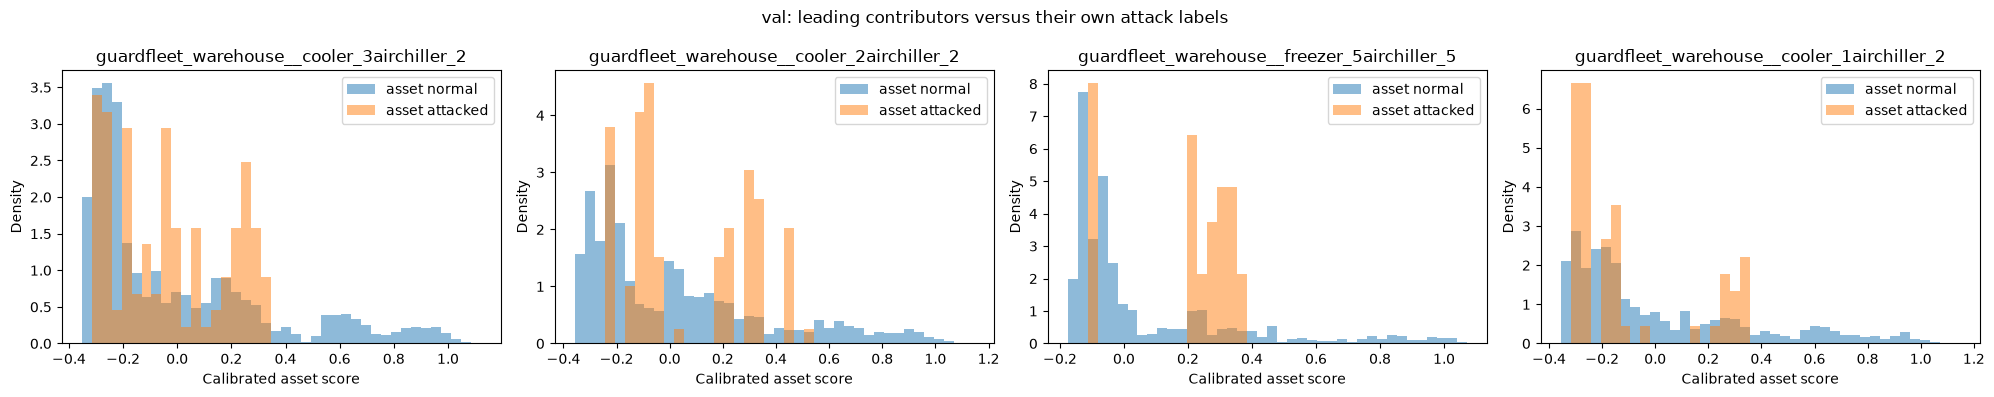


test: per-asset results (NaN metrics mean one or both classes are absent)
                                                   training_center  training_scale  labeled_timestamps  unknown_labels  own_attack_timestamps  attack_fraction  own_roc_auc  own_average_precision  normal_score_median  attack_score_median  mean_squared_contribution  mean_contribution_share  highest_contributor_fraction
asset                                                                                                                                                                                                                                                                                                                         
guardfleet_warehouse__cooler_3airchiller_2                0.459781        0.219412                7200               0                      0         0.000000          NaN                    NaN            -0.044000                  NaN                   0.096214                 0.03721

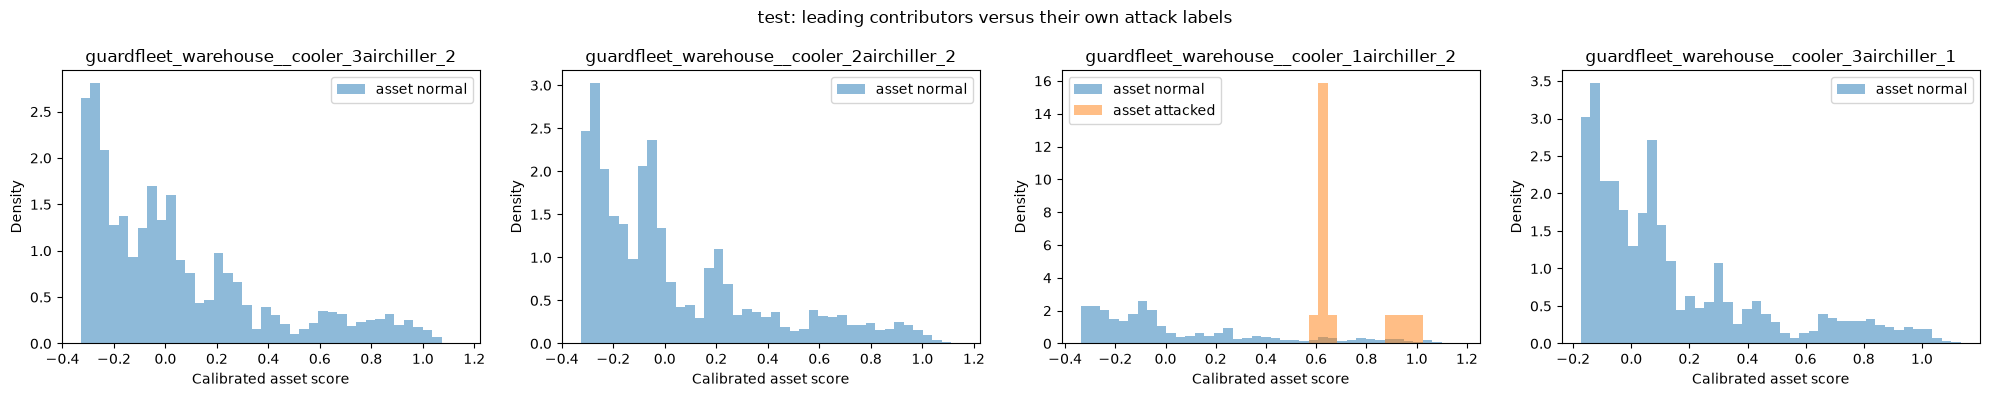


Interpretation: compare average precision with that asset's attack fraction.
Near-0.5 ROC-AUC indicates weak separation; assets with no attacks cannot be evaluated for detection.
Scores are normalized with held-out training statistics (median and 99th-percentile tail).
Validation tables are descriptive (validation labels also select the threshold). Test is diagnostic only.


In [12]:
# Per-asset attack attribution and normalization analysis.
# Diagnostic only: these results do not change models or thresholds.
def load_asset_attack_labels(path):
    if not LONG_FORMAT or not LABEL_COL:
        raise ValueError("Asset analysis requires long-format data with attack labels")
    keys = ([FACILITY_COL] if FACILITY_COL else []) + ["asset_id"]
    use = list(dict.fromkeys([TIMESTAMP_COL, LABEL_COL] + keys))
    reduced = []
    for raw in pd.read_csv(path, usecols=use, chunksize=250_000):
        raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], errors="coerce")
        raw = raw.dropna(subset=[TIMESTAMP_COL])
        if not raw[LABEL_COL].isin([0, 1]).all():
            raise ValueError(f"Invalid attack labels in {path}")
        asset = raw[keys[0]].astype(str)
        for key in keys[1:]:
            asset = asset + "__" + raw[key].astype(str)
        raw["asset"] = asset
        reduced.append(raw.groupby([TIMESTAMP_COL, "asset"])[LABEL_COL].max())
    labels = pd.concat(reduced).groupby(level=[0, 1]).max().unstack("asset")
    if RESAMPLE_RULE:
        labels = labels.resample(RESAMPLE_RULE).max()
    return labels

asset_analysis_tables = {}
for split_name, asset_scores in [("val", if_val_assets), ("test", if_test_assets)]:
    own_labels = load_asset_attack_labels(paths[split_name]).reindex(
        index=asset_scores.index, columns=asset_scores.columns)
    contributions = asset_scores.clip(lower=0).pow(2)
    total = contributions.sum(axis=1)
    shares = contributions.div(total.where(total > 0), axis=0).fillna(0)
    winners = contributions.idxmax(axis=1).where(total > 0)
    rows = []
    for asset, entry in iforest_bundle["assets"].items():
        label = own_labels[asset]
        valid = label.notna()
        scores = asset_scores.loc[valid, asset].to_numpy()
        truth = label[valid].to_numpy(dtype=int)
        normal = scores[truth == 0]
        attacked = scores[truth == 1]
        both = len(np.unique(truth)) == 2
        rows.append(dict(
            asset=asset, training_center=entry["center"], training_scale=entry["scale"],
            labeled_timestamps=int(valid.sum()), unknown_labels=int((~valid).sum()),
            own_attack_timestamps=int(truth.sum()),
            attack_fraction=float(truth.mean()) if len(truth) else np.nan,
            own_roc_auc=roc_auc_score(truth, scores) if both else np.nan,
            own_average_precision=average_precision_score(truth, scores) if both else np.nan,
            normal_score_median=float(np.median(normal)) if len(normal) else np.nan,
            attack_score_median=float(np.median(attacked)) if len(attacked) else np.nan,
            mean_squared_contribution=float(contributions[asset].mean()),
            mean_contribution_share=float(shares[asset].mean()),
            highest_contributor_fraction=float((winners == asset).mean()),
        ))
    table = pd.DataFrame(rows).set_index("asset")
    asset_analysis_tables[split_name] = table
    print(f"\n{split_name}: per-asset results (NaN metrics mean one or both classes are absent)")
    print(table.sort_values("mean_contribution_share", ascending=False).to_string())
    print("\nSmallest training normalization scales:")
    print(table[["training_scale", "mean_contribution_share", "own_roc_auc"]]
          .sort_values("training_scale").head(10).to_string())
    table.to_csv(OUTPUT_DIR / f"iforest_asset_analysis_{split_name}.csv")

    # Visualize the top contributors using their OWN labels.
    top = table.sort_values("mean_contribution_share", ascending=False).head(4).index
    fig, axes = plt.subplots(1, len(top), figsize=(5 * len(top), 4), squeeze=False)
    for ax, asset in zip(axes[0], top):
        values = asset_scores[asset]
        edges = np.histogram_bin_edges(values, bins=40)
        for label, title in [(0, "asset normal"), (1, "asset attacked")]:
            selected = values[own_labels[asset] == label]
            if len(selected):
                ax.hist(selected, bins=edges, density=True, alpha=.5, label=title)
        ax.set(title=asset, xlabel="Calibrated asset score", ylabel="Density")
        ax.legend()
    fig.suptitle(f"{split_name}: leading contributors versus their own attack labels")
    plt.tight_layout(); plt.show()

print("\nInterpretation: compare average precision with that asset's attack fraction.")
print("Near-0.5 ROC-AUC indicates weak separation; assets with no attacks cannot be evaluated for detection.")
print("Scores are normalized with held-out training statistics (median and 99th-percentile tail).")
print("Validation tables are descriptive (validation labels also select the threshold). Test is diagnostic only.")


## 3. LSTM forecaster
Input: the previous `WINDOW` samples. Target: the next sample. Trained on mostly-normal data, so it predicts normal behaviour well and has large errors on anomalies. The whole series is kept on the GPU and batches are built by indexing, which avoids materialising every window.

Windows stay within each file. The first `WINDOW` timestamps of each file provide history and are excluded from LSTM scoring.


The larger model uses 3 recurrent layers with 128 hidden units and a nonlinear prediction head. Dropout and early stopping limit overfitting. Keep the 60-step history for comparison; use validation metrics to judge improvements before final test evaluation. Training takes more time and memory.


In [13]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_feat, hidden, layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Linear(hidden, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, n_feat),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1])

def to_tensor(arr):
    return torch.from_numpy(np.array(arr, dtype=np.float32, order="C", copy=True)).to(DEVICE)

def batches(arr, window, batch_size, shuffle, valid=None):
    # valid: optional bool mask over windows; only True windows are used
    n_win = len(arr) - window
    pool = torch.arange(n_win, device=arr.device) if valid is None else torch.nonzero(valid).squeeze(1)
    idx = pool[torch.randperm(len(pool), device=arr.device)] if shuffle else pool
    ar = torch.arange(window, device=arr.device)
    for s in range(0, len(idx), batch_size):
        b = idx[s:s + batch_size]
        yield arr[b[:, None] + ar], arr[b + window]

def clean_window_mask(a, b):
    # a window (WINDOW history rows + its target row) is "clean" if none of those rows are attack rows
    if not USE_CLEAN:
        return None
    start = a
    att = attack[start:b].astype(np.int32)
    c = np.concatenate([[0], np.cumsum(att)])
    n_win = len(att) - WINDOW
    ok = (c[WINDOW + 1: WINDOW + 1 + n_win] - c[:n_win]) == 0
    return torch.from_numpy(ok).to(DEVICE)

def with_context(a, b):
    # Each file supplies its own history; its first WINDOW timestamps are warm-up.
    return S.iloc[a:b].values

train_t = to_tensor(S.iloc[:i_train].values)
train_ok = clean_window_mask(0, i_train)
val_ok_t = clean_window_mask(*splits["val"])
val_t   = to_tensor(with_context(*splits["val"]))
test_t  = to_tensor(with_context(*splits["test"]))

if train_ok is not None and not train_ok.any().item():
    raise ValueError("No clean training windows available")
if val_ok_t is not None and not val_ok_t.any().item():
    raise ValueError("No clean validation windows available")

model = LSTMForecaster(len(feat_cols), HIDDEN, LAYERS, DROPOUT).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
loss_fn = nn.MSELoss()
print("Parameters:", sum(p.numel() for p in model.parameters()))

@torch.no_grad()
def eval_loss(arr, valid=None):
    model.eval()
    tot, cnt = 0.0, 0
    for xb, yb in batches(arr, WINDOW, BATCH_SIZE * 2, shuffle=False, valid=valid):
        tot += loss_fn(model(xb), yb).item() * len(xb); cnt += len(xb)
    return tot / max(cnt, 1)

best, bad, history = float("inf"), 0, []
for epoch in range(1, EPOCHS + 1):
    model.train()
    tot, cnt, t0 = 0.0, 0, time.time()
    for xb, yb in batches(train_t, WINDOW, BATCH_SIZE, shuffle=True, valid=train_ok):
        opt.zero_grad(set_to_none=True)
        loss = loss_fn(model(xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        tot += loss.item() * len(xb); cnt += len(xb)
    tr, va = tot / cnt, eval_loss(val_t, val_ok_t)
    sched.step(va); history.append((tr, va))
    print(f"epoch {epoch:02d}  train {tr:.5f}  val {va:.5f}  ({time.time() - t0:.1f}s)")
    if va < best - 1e-6:
        best, bad = va, 0
        torch.save(model.state_dict(), OUTPUT_DIR / "lstm_best_v2.pt")
    else:
        bad += 1
        if bad >= PATIENCE:
            print("Early stopping"); break

model.load_state_dict(torch.load(OUTPUT_DIR / "lstm_best_v2.pt", map_location=DEVICE))

Parameters: 546871


epoch 01  train 0.31197  val 0.09871  (87.4s)
epoch 02  train 0.13787  val 0.06729  (86.4s)
epoch 03  train 0.11035  val 0.05755  (86.0s)
epoch 04  train 0.09685  val 0.05293  (86.0s)
epoch 05  train 0.09012  val 0.05104  (86.2s)
epoch 06  train 0.08555  val 0.04952  (86.1s)
epoch 07  train 0.08205  val 0.04667  (86.8s)
epoch 08  train 0.07983  val 0.04571  (85.9s)
epoch 09  train 0.07706  val 0.04479  (86.2s)
epoch 10  train 0.07585  val 0.04330  (85.7s)
epoch 11  train 0.07410  val 0.04366  (85.7s)
epoch 12  train 0.07264  val 0.04137  (85.8s)
epoch 13  train 0.07132  val 0.04027  (85.5s)
epoch 14  train 0.07025  val 0.04065  (85.4s)
epoch 15  train 0.06924  val 0.03920  (85.5s)
epoch 16  train 0.06791  val 0.03791  (85.3s)
epoch 17  train 0.06740  val 0.03734  (85.8s)
epoch 18  train 0.06680  val 0.03753  (86.0s)
epoch 19  train 0.06609  val 0.03745  (85.7s)
epoch 20  train 0.06535  val 0.03687  (85.4s)
epoch 21  train 0.06436  val 0.03656  (85.5s)
epoch 22  train 0.06414  val 0.035

<All keys matched successfully>

In [16]:
torch.save(model.state_dict(), 'model_weights.pth')

LSTM (mean error) threshold: 0.32516706 (validation_f1)
  Validation: precision 0.885  recall 0.590  F1 0.708  flagged 1,421/7,140 (19.90%)
LSTM (per-feature top-k) threshold: 1503.0844 (validation_f1)
  Validation: precision 0.992  recall 0.895  F1 0.941  flagged 1,923/7,140 (26.93%)


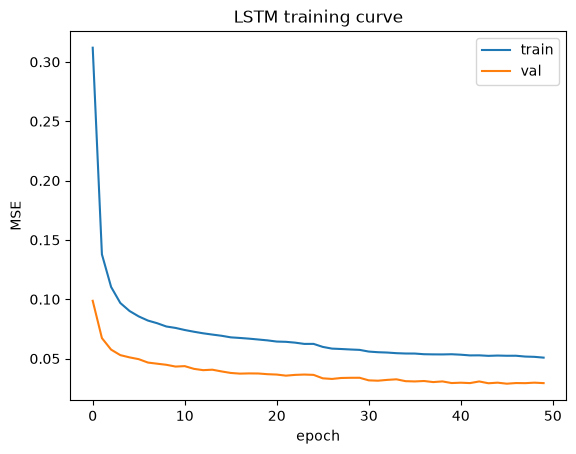

In [14]:
@torch.no_grad()
def lstm_errors(arr):
    # squared prediction error for every feature of every scored window -> (n_windows, n_features)
    model.eval()
    errs = []
    for xb, yb in batches(arr, WINDOW, BATCH_SIZE * 2, shuffle=False):
        errs.append(((model(xb) - yb) ** 2).cpu())
    return torch.cat(errs).numpy()

err_val, err_test = lstm_errors(val_t), lstm_errors(test_t)

# Score 1 (original): error averaged over ALL features.
lstm_val, lstm_test = err_val.mean(axis=1), err_test.mean(axis=1)

# Score 2: per-feature standardized error, keep the largest few. An attack usually corrupts one or two of the
# ~300 features, so averaging over all of them dilutes it. Each feature's error is divided by its own typical
# error (95th percentile on clean validation windows), then the top-k are averaged.
clean_val = val_ok_t.cpu().numpy().astype(bool) if val_ok_t is not None else np.ones(len(err_val), dtype=bool)
feat_scale = np.maximum(np.quantile(err_val[clean_val], 0.95, axis=0), 1e-8)

def lstm_feature_score(err, scale=feat_scale, k=LSTM_TOPK):
    z = err / scale
    k = min(max(int(k), 1), z.shape[1])
    return np.sort(z, axis=1)[:, -k:].mean(axis=1)

lstm_z_val, lstm_z_test = lstm_feature_score(err_val), lstm_feature_score(err_test)

# Match labels to targets after the within-file warm-up.
lstm_val_labels = val_labels[WINDOW:] if val_labels is not None else None
lstm_thr, lstm_threshold_method = choose_threshold("LSTM (mean error)", lstm_val, lstm_val_labels)
lstm_z_thr, lstm_z_threshold_method = choose_threshold("LSTM (per-feature top-k)", lstm_z_val, lstm_val_labels)

plt.plot([h[0] for h in history], label="train"); plt.plot([h[1] for h in history], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.title("LSTM training curve"); plt.show()

## 3b. Autoencoder
Input: the last `AE_WINDOW` timesteps of **all** features, flattened. The network squeezes them through a small bottleneck and tries to rebuild them. It is trained only on clean (attack-free) windows, so it learns the normal relationships between signals (for example chiller power versus outdoor temperature). A value that is plausible alone but inconsistent with the other features reconstructs badly. The score for a timestep is the reconstruction error of that window's **last** step.

As with the LSTM, two scores are produced: the error averaged over all features, and a per-feature standardized score that keeps only the largest few (an attack usually corrupts one or two of ~300 features, which averaging dilutes). Windows stay within each file, so the first `AE_WINDOW - 1` timesteps of each file are warm-up and are not scored. Set `RUN_AUTOENCODER = False` to skip this section.

Autoencoder type: gru
Autoencoder parameters: 928343


epoch 01  train 0.16942  val 0.08366  (19.0s)
epoch 02  train 0.06850  val 0.05722  (18.8s)
epoch 03  train 0.04859  val 0.04331  (18.7s)
epoch 04  train 0.03862  val 0.03666  (19.5s)
epoch 05  train 0.03363  val 0.03458  (18.9s)
epoch 06  train 0.03029  val 0.03131  (18.8s)
epoch 07  train 0.02738  val 0.02793  (18.7s)
epoch 08  train 0.02521  val 0.02716  (19.0s)
epoch 09  train 0.02396  val 0.02924  (18.5s)
epoch 10  train 0.02214  val 0.02569  (18.6s)
epoch 11  train 0.02128  val 0.02482  (18.7s)
epoch 12  train 0.01961  val 0.02428  (18.9s)
epoch 13  train 0.01977  val 0.02309  (18.8s)
epoch 14  train 0.01853  val 0.02220  (18.8s)
epoch 15  train 0.01802  val 0.02410  (18.8s)
epoch 16  train 0.01771  val 0.02321  (18.7s)
epoch 17  train 0.01790  val 0.02036  (18.6s)
epoch 18  train 0.01622  val 0.02108  (18.4s)
epoch 19  train 0.01563  val 0.02251  (18.6s)
epoch 20  train 0.01577  val 0.02250  (18.6s)
epoch 21  train 0.01266  val 0.01716  (18.6s)
epoch 22  train 0.01198  val 0.017

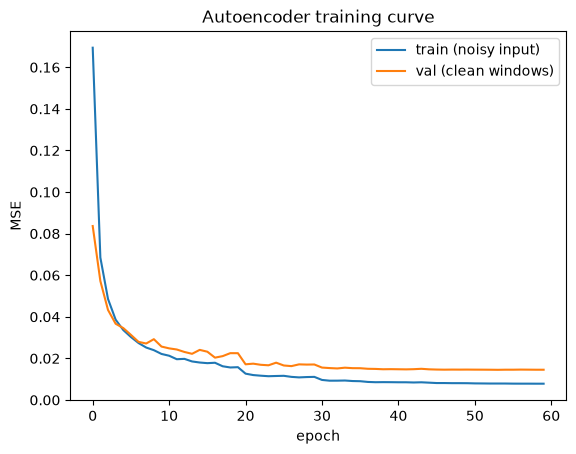

In [20]:
if not RUN_AUTOENCODER:
    print("RUN_AUTOENCODER is False; autoencoder skipped")
else:
    torch.manual_seed(SEED)
    AE_LEAD = AE_WINDOW - 1            # leading rows of each file without an autoencoder score
    N_FEAT = len(feat_cols)

    def _tensor(a):
        return torch.from_numpy(np.array(a, dtype=np.float32, order="C", copy=True)).to(DEVICE)

    class WindowAutoencoder(nn.Module):
        def __init__(self, n_feat, window, hidden, bottleneck, dropout):
            super().__init__()
            n_in = n_feat * window
            self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.GELU(), nn.Dropout(dropout),
                                         nn.Linear(hidden, bottleneck))
            self.decoder = nn.Sequential(nn.Linear(bottleneck, hidden), nn.GELU(),
                                         nn.Linear(hidden, n_in))

        def forward(self, x):                      # x: (batch, window * n_feat)
            return self.decoder(self.encoder(x))

    class GRUAutoencoder(nn.Module):
        # Same interface as WindowAutoencoder: takes and returns FLATTENED windows (batch, window * n_feat).
        # Internally the window is a sequence of `window` steps with `n_feat` features each, so the GRU's
        # input_size is n_feat (NOT window * n_feat) and its input is 3-D: (batch, window, n_feat).
        def __init__(self, n_feat, window, hidden, bottleneck, dropout):
            super().__init__()
            self.n_feat, self.window = n_feat, window
            self.enc_gru = nn.GRU(n_feat, hidden, batch_first=True)
            self.drop = nn.Dropout(dropout)
            self.to_latent = nn.Linear(hidden, bottleneck)
            self.from_latent = nn.Linear(bottleneck, hidden)
            self.dec_gru = nn.GRU(hidden, hidden, batch_first=True)
            self.out = nn.Linear(hidden, n_feat)

        def forward(self, x):                                # x: (batch, window * n_feat)
            b = x.shape[0]
            seq = x.reshape(b, self.window, self.n_feat)     # (batch, window, n_feat)
            _, h = self.enc_gru(seq)                         # h: (1, batch, hidden) = summary of the window
            z = self.to_latent(self.drop(h[-1]))             # (batch, bottleneck)
            dec_in = self.from_latent(z).unsqueeze(1).repeat(1, self.window, 1)   # (batch, window, hidden)
            dec_out, _ = self.dec_gru(dec_in)                # (batch, window, hidden)
            return self.out(dec_out).reshape(b, -1)          # (batch, window * n_feat)

    def ae_batches(arr, batch_size, shuffle, valid=None):
        # yields flattened windows of AE_WINDOW consecutive rows; valid = optional bool mask over windows
        n_win = len(arr) - AE_WINDOW + 1
        pool = torch.arange(n_win, device=arr.device) if valid is None else torch.nonzero(valid).squeeze(1)
        idx = pool[torch.randperm(len(pool), device=arr.device)] if shuffle else pool
        ar = torch.arange(AE_WINDOW, device=arr.device)
        for s in range(0, len(idx), batch_size):
            b = idx[s:s + batch_size]
            yield arr[b[:, None] + ar].reshape(len(b), -1)

    def ae_clean_mask(a, b):
        # a window is "clean" if none of its AE_WINDOW rows is an attack row
        if not USE_CLEAN:
            return None
        att = attack[a:b].astype(np.int32)
        c = np.concatenate([[0], np.cumsum(att)])
        n_win = len(att) - AE_WINDOW + 1
        ok = (c[AE_WINDOW: AE_WINDOW + n_win] - c[:n_win]) == 0
        return torch.from_numpy(ok).to(DEVICE)

    ae_train_t = _tensor(S.iloc[:i_train].values)
    ae_val_t = _tensor(S.iloc[splits["val"][0]:splits["val"][1]].values)
    ae_test_t = _tensor(S.iloc[splits["test"][0]:splits["test"][1]].values)
    for _name, _t in [("train", ae_train_t), ("val", ae_val_t), ("test", ae_test_t)]:
        if len(_t) < AE_WINDOW:
            raise ValueError(f"{_name} needs at least AE_WINDOW={AE_WINDOW} timesteps")
    ae_train_ok = ae_clean_mask(0, i_train)
    ae_val_ok = ae_clean_mask(*splits["val"])
    if ae_train_ok is not None and not ae_train_ok.any().item():
        raise ValueError("No clean training windows for the autoencoder")
    if ae_val_ok is not None and not ae_val_ok.any().item():
        raise ValueError("No clean validation windows for the autoencoder")

    if AE_MODEL not in ("dense", "gru"):
        raise ValueError("AE_MODEL must be 'dense' or 'gru'")
    ae_class = WindowAutoencoder if AE_MODEL == "dense" else GRUAutoencoder
    ae = ae_class(N_FEAT, AE_WINDOW, AE_HIDDEN, AE_BOTTLENECK, AE_DROPOUT).to(DEVICE)
    print("Autoencoder type:", AE_MODEL)
    ae_opt = torch.optim.AdamW(ae.parameters(), lr=AE_LR, weight_decay=1e-4)
    ae_sched = torch.optim.lr_scheduler.ReduceLROnPlateau(ae_opt, factor=0.5, patience=2)
    ae_loss_fn = nn.MSELoss()
    print("Autoencoder parameters:", sum(p.numel() for p in ae.parameters()))

    @torch.no_grad()
    def ae_eval_loss(arr, valid=None):
        ae.eval()
        tot, cnt = 0.0, 0
        for xb in ae_batches(arr, AE_BATCH * 2, shuffle=False, valid=valid):
            tot += ae_loss_fn(ae(xb), xb).item() * len(xb); cnt += len(xb)
        return tot / max(cnt, 1)

    ae_best, ae_bad, ae_history = float("inf"), 0, []
    for epoch in range(1, AE_EPOCHS + 1):
        ae.train()
        tot, cnt, t0 = 0.0, 0, time.time()
        for xb in ae_batches(ae_train_t, AE_BATCH, shuffle=True, valid=ae_train_ok):
            noisy = xb + AE_NOISE * torch.randn_like(xb) if AE_NOISE > 0 else xb
            ae_opt.zero_grad(set_to_none=True)
            loss = ae_loss_fn(ae(noisy), xb)           # reconstruct the CLEAN window from the noisy one
            loss.backward()
            nn.utils.clip_grad_norm_(ae.parameters(), 1.0)
            ae_opt.step()
            tot += loss.item() * len(xb); cnt += len(xb)
        tr, va = tot / cnt, ae_eval_loss(ae_val_t, ae_val_ok)
        ae_sched.step(va); ae_history.append((tr, va))
        print(f"epoch {epoch:02d}  train {tr:.5f}  val {va:.5f}  ({time.time() - t0:.1f}s)")
        if va < ae_best - 1e-6:
            ae_best, ae_bad = va, 0
            torch.save(ae.state_dict(), OUTPUT_DIR / "autoencoder_best.pt")
        else:
            ae_bad += 1
            if ae_bad >= AE_PATIENCE:
                print("Early stopping"); break

    ae.load_state_dict(torch.load(OUTPUT_DIR / "autoencoder_best.pt", map_location=DEVICE))

    @torch.no_grad()
    def ae_errors(arr):
        # squared reconstruction error of the LAST step of each window, per feature -> (n_windows, n_features)
        ae.eval()
        errs = []
        for xb in ae_batches(arr, AE_BATCH * 2, shuffle=False):
            errs.append(((ae(xb) - xb)[:, -N_FEAT:] ** 2).cpu())
        return torch.cat(errs).numpy()

    ae_err_val, ae_err_test = ae_errors(ae_val_t), ae_errors(ae_test_t)

    # Score 1: error averaged over all features.
    ae_val, ae_test = ae_err_val.mean(axis=1), ae_err_test.mean(axis=1)

    # Score 2: per-feature standardized error, largest few. Each feature's error is divided by its own 95th
    # percentile on clean validation windows.
    ae_clean_val = ae_val_ok.cpu().numpy().astype(bool) if ae_val_ok is not None else np.ones(len(ae_err_val), dtype=bool)
    ae_feat_scale = np.maximum(np.quantile(ae_err_val[ae_clean_val], 0.95, axis=0), 1e-8)

    def ae_feature_score(err, scale=ae_feat_scale, k=AE_TOPK):
        z = err / scale
        k = min(max(int(k), 1), z.shape[1])
        return np.sort(z, axis=1)[:, -k:].mean(axis=1)

    ae_z_val, ae_z_test = ae_feature_score(ae_err_val), ae_feature_score(ae_err_test)

    ae_val_labels = val_labels[AE_LEAD:] if val_labels is not None else None
    ae_thr, ae_threshold_method = choose_threshold("Autoencoder (mean error)", ae_val, ae_val_labels)
    ae_z_thr, ae_z_threshold_method = choose_threshold("Autoencoder (per-feature top-k)", ae_z_val, ae_val_labels)

    plt.plot([h[0] for h in ae_history], label="train (noisy input)"); plt.plot([h[1] for h in ae_history], label="val (clean windows)")
    plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.title("Autoencoder training curve"); plt.show()

In [22]:
torch.save(ae.state_dict(), 'gru_model_weights.pth')

## 4. Evaluate

[IsolationForest] test rows: 7,200   flagged: 7,200 (100.00%)
   ROC-AUC 0.503   PR-AUC 0.028   precision 0.029   recall 1.000   F1 0.057
[LSTM mean error] test rows: 7,140   flagged: 271 (3.80%)
   ROC-AUC 0.846   PR-AUC 0.383   precision 0.513   recall 0.662   F1 0.578
[LSTM per-feature top-k] test rows: 7,140   flagged: 284 (3.98%)
   ROC-AUC 0.954   PR-AUC 0.870   precision 0.634   recall 0.857   F1 0.729
[Autoencoder mean error] test rows: 7,191   flagged: 1,089 (15.14%)
   ROC-AUC 0.855   PR-AUC 0.627   precision 0.138   recall 0.714   F1 0.231
[Autoencoder per-feature top-k] test rows: 7,191   flagged: 184 (2.56%)
   ROC-AUC 0.949   PR-AUC 0.868   precision 0.978   recall 0.857   F1 0.914

Test summary (thresholds chosen on validation):
                               roc_auc  pr_auc  precision  recall     f1  flagged
model                                                                            
IsolationForest                  0.503   0.028      0.029   1.000  0.057    1.000


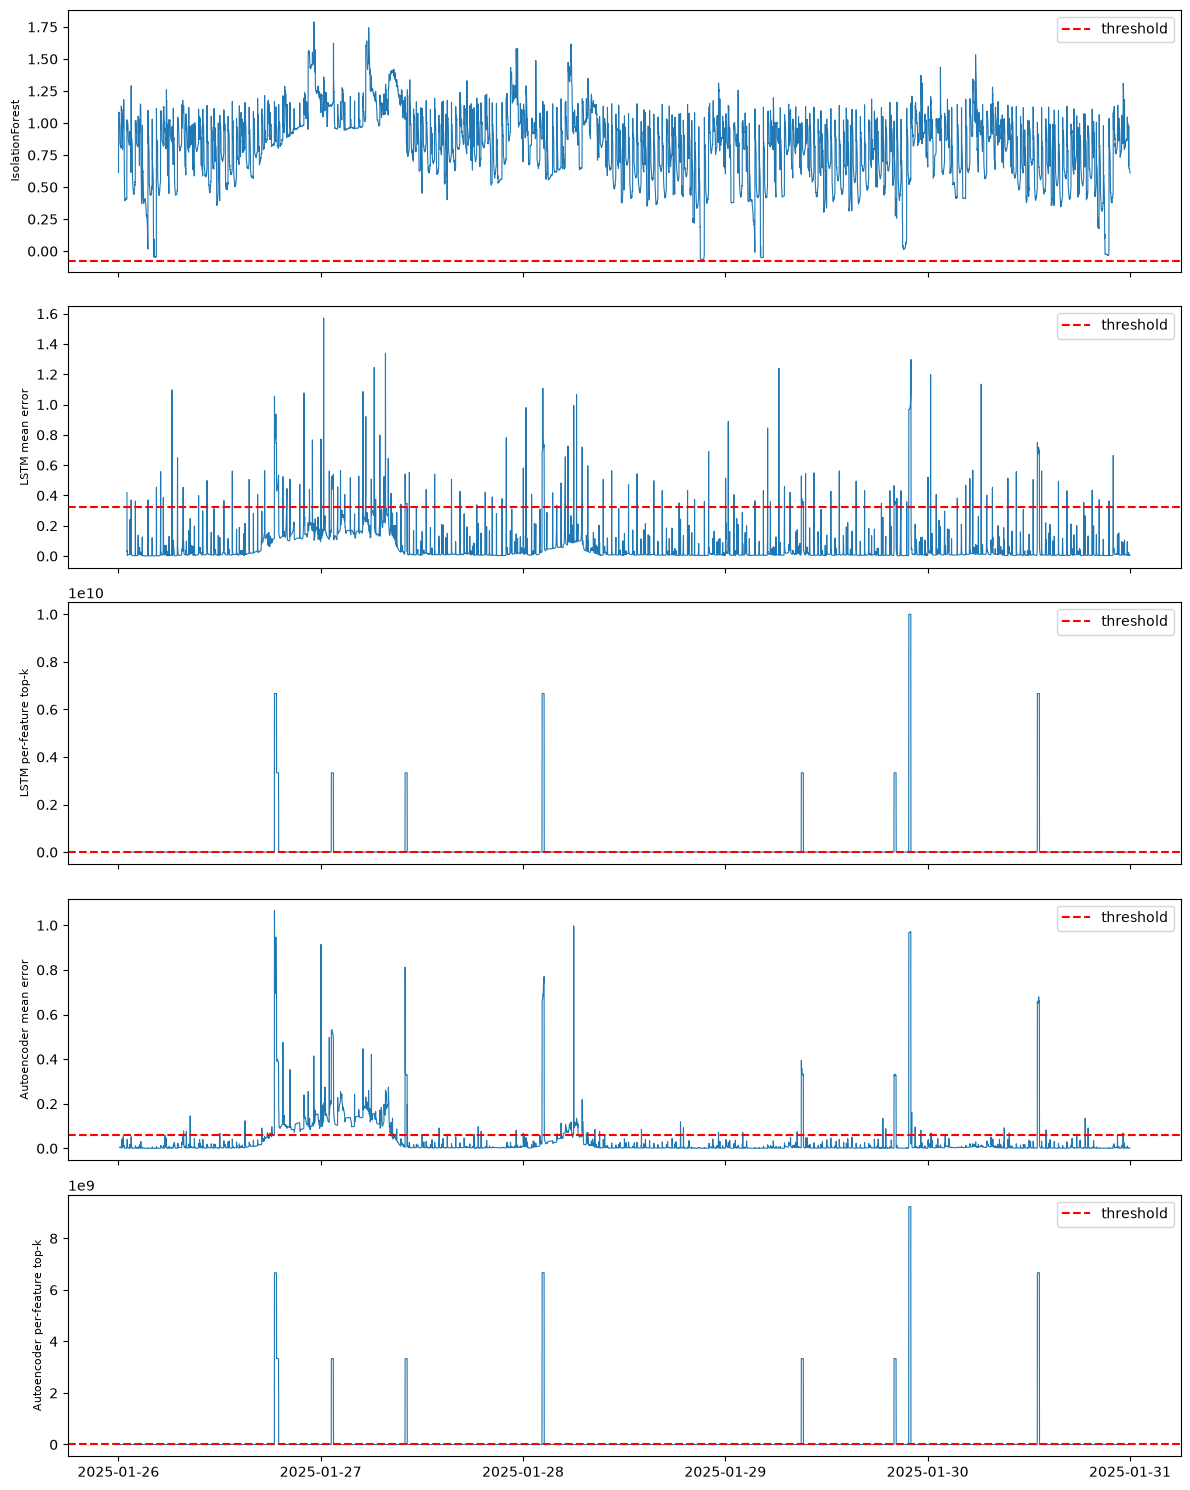

In [21]:
def report(name, scores, thr, a, b):
    flags = scores > thr
    print(f"[{name}] test rows: {len(scores):,}   flagged: {flags.sum():,} ({flags.mean():.2%})")
    if y is not None:
        yt = y.iloc[a:b].values[-len(scores):]
        if 0 < yt.sum() < len(yt):
            p, r, f, _ = precision_recall_fscore_support(yt, flags, average="binary", zero_division=0)
            print(f"   ROC-AUC {roc_auc_score(yt, scores):.3f}   PR-AUC {average_precision_score(yt, scores):.3f}   "
                  f"precision {p:.3f}   recall {r:.3f}   F1 {f:.3f}")
        else:
            print("   test slice has no positives or no negatives; metrics skipped")

models = [("IsolationForest", if_test, if_thr),
          ("LSTM mean error", lstm_test, lstm_thr),
          ("LSTM per-feature top-k", lstm_z_test, lstm_z_thr)]
if RUN_AUTOENCODER:
    models += [("Autoencoder mean error", ae_test, ae_thr),
               ("Autoencoder per-feature top-k", ae_z_test, ae_z_thr)]
for name, sc, thr in models:
    report(name, sc, thr, *splits["test"])

# Side-by-side summary on the test file
if y is not None:
    rows = []
    for name, sc, thr in models:
        yt, fl = y.iloc[splits["test"][0]:splits["test"][1]].values[-len(sc):], sc > thr
        if 0 < yt.sum() < len(yt):
            p, r, f, _ = precision_recall_fscore_support(yt, fl, average="binary", zero_division=0)
            rows.append(dict(model=name, roc_auc=roc_auc_score(yt, sc), pr_auc=average_precision_score(yt, sc),
                             precision=p, recall=r, f1=f, flagged=fl.mean()))
    if rows:
        print("\nTest summary (thresholds chosen on validation):")
        print(pd.DataFrame(rows).set_index("model").round(3).to_string())

fig, axes = plt.subplots(len(models), 1, figsize=(12, 3 * len(models)), sharex=True)
idx = X.index[splits["test"][0]:splits["test"][1]]
for ax, (name, sc, thr) in zip(axes, models):
    ax.plot(idx[-len(sc):], sc, lw=0.8); ax.axhline(thr, color="r", ls="--", label="threshold")
    ax.set_ylabel(name, fontsize=8); ax.legend()
plt.tight_layout(); plt.show()

Thresholds maximize F1 on **labeled validation data**, with ties resolved toward fewer alerts. Test labels are used only for final evaluation. Validation precision, recall, F1, and alert counts are printed during calibration. If validation lacks either class, calibration falls back to the normal-score percentile. Set `THRESHOLD_METHOD = "normal_percentile"` to choose that method explicitly.

Validation here has a much higher attack share than a realistic deployment, and the F1-optimal threshold depends on that share. If you know roughly how common attacks are in real use, set `VAL_PREVALENCE` in the config (for example `0.03`) so validation F1 is computed as if attacks made up that share. Choose it from domain knowledge, not by looking at the test labels.

## 5. Save artifacts

In [ ]:
joblib.dump(iforest_bundle, OUTPUT_DIR / "iforest_per_asset.joblib")
joblib.dump(scaler, OUTPUT_DIR / "scaler.joblib")

# Plain numpy export of the LSTM weights (useful if you later port the model elsewhere)
np.savez(OUTPUT_DIR / "lstm_weights.npz", **{k: v.cpu().numpy() for k, v in model.state_dict().items()})

meta = {
    "feature_cols": feat_cols,
    "fill_values": {c: float(fill_values[c]) for c in feat_cols},
    "max_gap_fill": MAX_GAP_FILL,
    "dataset_paths": {name: str(path) for name, path in paths.items()},
    "lstm_warmup_steps_per_split": WINDOW,
    "lstm_architecture": "lstm_layernorm_mlp_v2",
    "dropout": DROPOUT,
    "resample_rule": RESAMPLE_RULE,
    "long_format": LONG_FORMAT, "id_cols": ID_COLS, "value_col": VALUE_COL,
    "trained_on_normal_only": USE_CLEAN,
    "roll_windows": ROLL_WINDOWS,
    "window": WINDOW, "hidden": HIDDEN, "layers": LAYERS,
    "iforest_architecture": "per_asset_forest_heldout_median_q99_topk",
    "iforest_calibration": iforest_bundle["normalization"],
    "iforest_aggregation": iforest_bundle["aggregation"],
    "iforest_threshold": if_thr, "lstm_threshold": lstm_thr,
    "lstm_feature_topk": LSTM_TOPK, "lstm_feature_scale": [float(v) for v in feat_scale],
    "lstm_feature_threshold": lstm_z_thr, "lstm_feature_threshold_method": lstm_z_threshold_method,
    "val_prevalence": VAL_PREVALENCE,
    "threshold_percentile": THRESHOLD_PCTL,
    "threshold_method_requested": THRESHOLD_METHOD,
    "iforest_threshold_method": if_threshold_method,
    "lstm_threshold_method": lstm_threshold_method,
}
if RUN_AUTOENCODER:
    meta["autoencoder"] = {
        "weights": "autoencoder_best.pt", "window": AE_WINDOW, "hidden": AE_HIDDEN, "bottleneck": AE_BOTTLENECK,
        "dropout": AE_DROPOUT, "noise": AE_NOISE, "topk": AE_TOPK,
        "mean_error_threshold": ae_thr, "mean_error_threshold_method": ae_threshold_method,
        "feature_threshold": ae_z_thr, "feature_threshold_method": ae_z_threshold_method,
        "feature_scale": [float(v) for v in ae_feat_scale],
    }
(OUTPUT_DIR / "meta.json").write_text(json.dumps(meta, indent=2))
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

['autoencoder_best.pt', 'iforest.joblib', 'iforest_asset_analysis_test.csv', 'iforest_asset_analysis_val.csv', 'iforest_per_asset.joblib', 'lstm_best.pt', 'lstm_best_v2.pt', 'lstm_weights.npz', 'meta.json', 'scaler.joblib']


: 

## 6. Reload and score new data (reference)
Use the same cleaning, scaling and feature steps as above, then:

```python
iforest_bundle = joblib.load("outputs/iforest_per_asset.joblib")
scaler  = joblib.load("outputs/scaler.joblib")
meta    = json.load(open("outputs/meta.json"))
# IF: use make_features and score_asset_forests from above:
# scores, asset_scores = score_asset_forests(iforest_bundle, make_features(scaled_df))
# flags = scores > meta["iforest_threshold"]
# LSTM: rebuild LSTMForecaster(len(meta["feature_cols"]), meta["hidden"], meta["layers"], 0.0),
#       load outputs/lstm_best_v2.pt, score windows of meta["window"] rows; anomaly if error > meta["lstm_threshold"]
# Autoencoder: rebuild WindowAutoencoder(len(meta["feature_cols"]), a["window"], a["hidden"], a["bottleneck"], 0.0) with a = meta["autoencoder"],
#       load outputs/autoencoder_best.pt, take the last-step error of each window; anomaly if per-feature score > a["feature_threshold"]
```